Praktikum Week 12 RNN dan LTSM 

Nama    : Gresia Delia Silalahi

NIM     : 42324011

Topik   : Time Series Forecasting dengan RNN dan LSTM pada dataset 'RSCASN.csv'

In [1]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


#### Penjelasan :
##### Instalasi Pustaka TensorFlow
##### Pada sel pertama sesuai dokumen modul sesi teori, program menjalankan perintah instalasi kerangka kerja pembelajaran mendalam yaitu TensorFlow agar seluruh fungsi pembentukan model jaringan saraf berulang dan memori jangka panjang tersedia di lingkungan kerja Python sebelum digunakan. Jika dijalankan pada Google Colab yang umumnya sudah menyediakan pustaka tersebut secara bawaan, keluaran pada layar menampilkan keterangan bahwa paket beserta dependensi pendukungnya sudah terpasang atau memperbarui versi yang diperlukan sehingga lingkungan kerja siap melanjutkan ke tahap pemanggilan modul.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.dates as mdates

#### Penjelasan :
##### Import Seluruh Library yang Dibutuhkan
##### Pada sel kedua, program memanggil seluruh pustaka Python persis seperti pada dokumen teori mulai dari pengolah larik numerik, pengolah tabel data berbasis tanggal, pembuat grafik dan gaya visualisasi statistik, kerangka kerja pembelajaran mendalam beserta pembangkit urutan deret waktu, penyekala data rentang nol hingga satu, pembentuk model berurutan, lapisan jaringan berulang sederhana, lapisan memori jangka panjang, lapisan pencegah penghafalan berlebih, lapisan keluaran padat, fitur penghenti pelatihan otomatis, hingga pemformat penanggalan pada sumbu grafik. Sel ini tidak mencetak angka atau gambar di layar, melainkan menandakan bahwa seluruh komponen analisis dan pemodelan berhasil dimuat ke dalam memori.

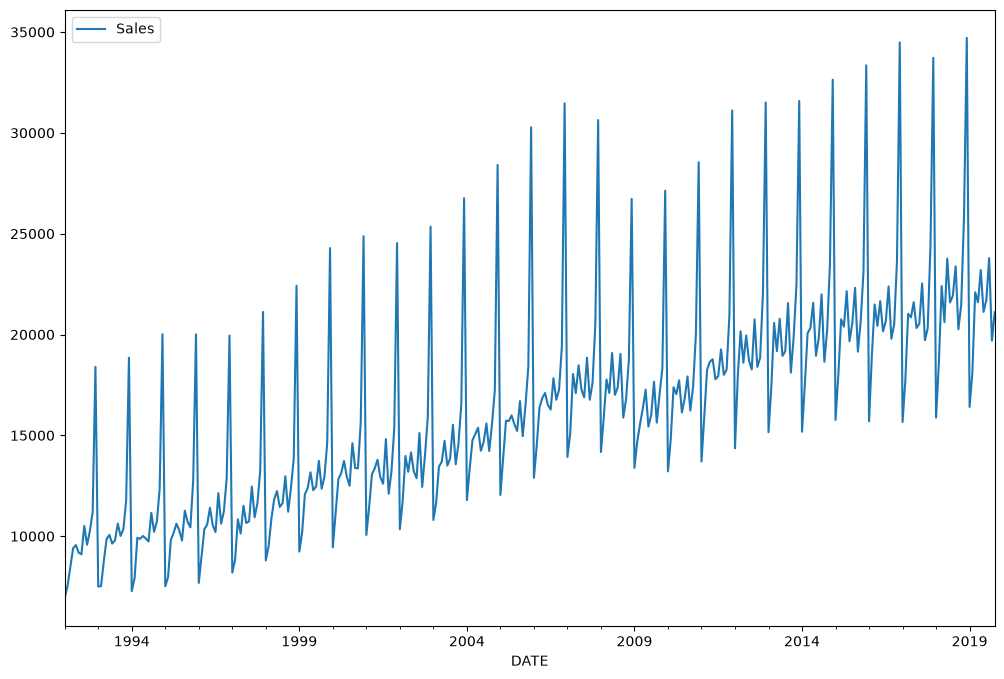

In [3]:
# Membaca dataset
dataset_path = 'RSCCASN.csv'
sales_data = pd.read_csv(dataset_path, parse_dates=True, index_col='DATE')
sales_data.columns = ['Sales']

# Plot data penjualan
sales_data.plot(figsize=(12, 8))

# Train-test split
test_size = 18
test_index = len(sales_data) - test_size
train = sales_data.iloc[:test_index]
test = sales_data.iloc[test_index:]

#### Penjelasan :
##### Membaca Dataset, Plot Data Penjualan, dan Train-Test Split
##### Pada sel ketiga, program membaca berkas data penjualan ritel pakaian dan aksesori bulanan dari file RSCCASN dengan mengubah kolom tanggal menjadi indeks waktu berurutan serta mengganti nama kolom nilai penjualan menjadi satu nama seragam seperti pada dokumen teori, lalu langsung menggambar grafik garis seluruh data historis dan membagi data menjadi bagian latih serta bagian uji sebanyak delapan belas bulan terakhir tanpa mengacak urutannya agar kronologi waktu tetap terjaga. Keluaran di layar menampilkan grafik deret waktu penjualan dari tahun seribu sembilan ratus sembilan puluh dua hingga dua ribu sembilan belas yang memperlihatkan tren kenaikan jangka panjang yang konsisten disertai lonjakan tajam yang berulang di setiap akhir tahun.

In [4]:
# Inisialisasi MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(train)

# Transformasi data train dan test
scaled_train = scaler.transform(train)
scaled_test = scaler.transform(test)

#### Penjelasan :
##### Normalisasi Data dengan MinMaxScaler
##### Pada sel keempat, program melakukan penskalaan angka penjualan ke rentang nol hingga satu menggunakan metode minimum dan maksimum seperti pada materi teori sesi satu agar nilai masukan yang masuk ke fungsi aktivasi jaringan berulang selalu berada pada skala kecil yang stabil. Perhitungan nilai terkecil dan terbesar hanya dipelajari dari data latih melalui fungsi penyesuaian guna mencegah kebocoran informasi dari data uji, lalu diterapkan pada data latih maupun data uji untuk menghasilkan larik data ternormalisasi. Sel ini tidak menampilkan cetakan di layar karena hasil transformasinya disimpan di variabel untuk digunakan pada sel berikutnya.

In [5]:
# Membuat generator data time series
length = 12  # Panjang input (12 bulan)
n_features = 1
generator = TimeseriesGenerator(scaled_train, scaled_train, length=length, batch_size=1)

#### Penjelasan :
##### Membuat Time Series Generator
##### Pada sel kelima, program menyusun data latih yang telah ternormalisasi menjadi pasangan jendela urutan masukan dan nilai target menggunakan pembangkit deret waktu dengan panjang sekuens dua belas bulan, satu fitur penjualan, dan ukuran satu sampel tiap langkah pembaruan bobot. Pemilihan panjang dua belas periode bertujuan agar model memperoleh informasi satu siklus musiman penuh selama setahun sebelum memperkirakan angka penjualan bulan ketigabelas. Sel ini tidak menampilkan tabel di layar, melainkan menyiapkan aliran tiga ratus empat pasangan data latih berurutan yang siap dimasukkan ke dalam pelatihan kedua model.

In [6]:
# Model SimpleRNN
model_rnn = Sequential()
model_rnn.add(SimpleRNN(100, activation='relu', input_shape=(length, n_features)))
model_rnn.add(Dense(1))
model_rnn.compile(optimizer='adam', loss='mse')
model_rnn.summary()

# Callback early stopping untuk RNN
early_stop_rnn = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Validation generator
validation_generator = TimeseriesGenerator(scaled_test, scaled_test, length=length, batch_size=1)

# Melatih model RNN
history_rnn = model_rnn.fit(generator, epochs=20, validation_data=validation_generator, callbacks=[early_stop_rnn])

c:\Users\ASUS\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 100)            │        10,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,301 (40.24 KB)

 Trainable params: 10,301 (40.24 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0198 - val_loss: 0.0038
Epoch 2/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0037 - val_loss: 7.7648e-04
Epoch 3/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0025 - val_loss: 6.6286e-04
Epoch 4/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0018 - val_loss: 5.9735e-04
Epoch 5/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0015 - val_loss: 0.0018
Epoch 6/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0021 - val_loss: 0.0044
Epoch 7/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0022 - val_loss: 0.0016


#### Penjelasan :
##### Membangun, Kompilasi, Validasi, dan Pelatihan Model SimpleRNN
##### Pada sel keenam, program membangun model pertama sesuai dokumen teori yaitu arsitektur jaringan saraf berulang sederhana dengan seratus unit aktivasi penyearah yang menerima masukan dua belas langkah waktu satu fitur, diikuti satu lapisan keluaran tunggal, lalu mengompilasinya memakai pengoptimal adaptif serta fungsi kesalahan kuadrat rata-rata dan menyiapkan penghenti pelatihan otomatis berbatas kesabaran tiga putaran beserta pembangkit validasi dari data uji. Keluaran pada layar menampilkan tabel ringkasan arsitektur dengan total sepuluh ribu tiga ratus satu parameter yang dapat dilatih serta catatan kemajuan nilai kesalahan latih dan kesalahan validasi tiap putaran hingga penghentian otomatis memulihkan bobot terbaik.

In [7]:
# Model LSTM dengan penambahan Dropout
model_lstm = Sequential()
model_lstm.add(LSTM(100, activation='relu', input_shape=(length, n_features)))
model_lstm.add(Dropout(0.2))  # Penambahan Dropout untuk mengurangi overfitting
model_lstm.add(Dense(1))
model_lstm.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
model_lstm.summary()

# Callback early stopping untuk LSTM
early_stop_lstm = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Melatih model LSTM
history_lstm = model_lstm.fit(generator, epochs=20, validation_data=validation_generator, callbacks=[early_stop_lstm])

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100)            │        40,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,901 (159.77 KB)

 Trainable params: 40,901 (159.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.0233 - val_loss: 0.0064
Epoch 2/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0209 - val_loss: 0.0096
Epoch 3/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0181 - val_loss: 0.0063
Epoch 4/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0103 - val_loss: 0.0058
Epoch 5/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0056 - val_loss: 0.0027
Epoch 6/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0088 - val_loss: 0.0023
Epoch 7/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0049 - val_loss: 0.0035
Epoch 8/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0028 - val_loss: 3.7146e-04
Epoch 9/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0026 - val_loss: 0.0014
Epoch 10/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0033 - val_loss: 0.0071
Epoch 11/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0022 - val_loss: 6.0527e-04
Epoch 12/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 

#### Penjelasan :
##### Membangun, Kompilasi, dan Pelatihan Model LSTM dengan Dropout
##### Pada sel ketujuh, program membangun model kedua sesuai dokumen teori yaitu arsitektur memori jangka panjang berkapasitas seratus unit aktivasi penyearah yang di dalamnya bekerja mekanisme empat gerbang seperti pada teori sesi satu, dilengkapi lapisan pelepasan acak dua puluh persen untuk mencegah penghafalan berlebih dan satu lapisan keluaran tunggal, lalu mengompilasinya dengan pengoptimal adaptif berlaju belajar nol koma nol nol satu serta penghenti pelatihan otomatis berbatas kesabaran lima putaran. Keluaran pada layar menampilkan tabel ringkasan sebanyak empat puluh ribu sembilan ratus satu parameter, yakni sekitar empat kali lipat parameter jaringan berulang sederhana akibat adanya empat gerbang internal, disertai proses penurunan nilai kesalahan di setiap putaran pelatihan.

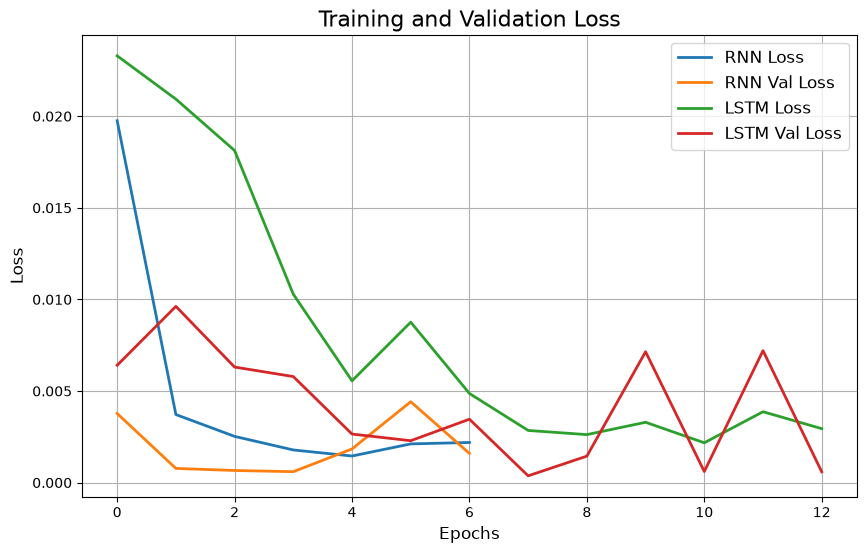

In [8]:
# Fungsi untuk plot training dan validation loss
def plot_loss(history_rnn, history_lstm):
    # Plot the training and validation loss
    losses_rnn = pd.DataFrame(history_rnn.history)
    losses_lstm = pd.DataFrame(history_lstm.history)

    plt.figure(figsize=(10, 6))
    plt.plot(losses_rnn['loss'], label='RNN Loss', linewidth=2)
    plt.plot(losses_rnn['val_loss'], label='RNN Val Loss', linewidth=2)
    plt.plot(losses_lstm['loss'], label='LSTM Loss', linewidth=2)
    plt.plot(losses_lstm['val_loss'], label='LSTM Val Loss', linewidth=2)
    plt.title('Training and Validation Loss', fontsize=16)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()

plot_loss(history_rnn, history_lstm)

#### Penjelasan :
##### Fungsi Plot Gabungan Training dan Validation Loss
##### Pada sel kedelapan, program mendefinisikan lalu menjalankan fungsi untuk menggambar perbandingan kurva kesalahan latih dan kesalahan validasi dari model jaringan berulang sederhana maupun memori jangka panjang dalam satu bidang grafik yang sama seperti pada dokumen teori. Riwayat kesalahan dari kedua model diubah menjadi tabel agar mudah diplot lengkap dengan judul, label sumbu, legenda, dan garis bantu kisi untuk memantau apakah pelatihan konvergen dengan baik. Keluaran grafik di layar memperlihatkan keempat garis kesalahan turun drastis sejak putaran awal dan berdekatan mendekati nol sehingga membuktikan kedua model belajar dengan baik tanpa mengalami kelebihan penyesuaian yang parah.

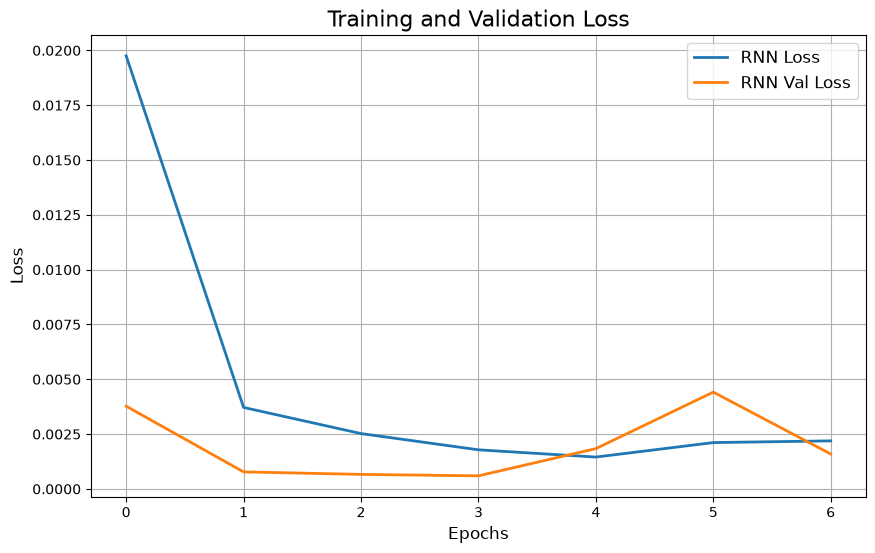

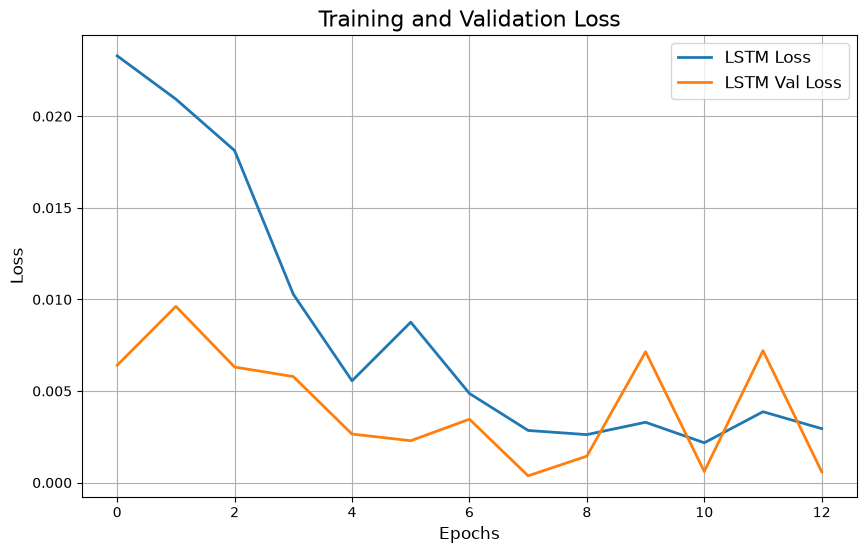

In [11]:
def plot_loss_rnn(history_rnn):
    # Plot the training and validation loss
    losses_rnn = pd.DataFrame(history_rnn.history)

    plt.figure(figsize=(10, 6))
    plt.plot(losses_rnn['loss'], label='RNN Loss', linewidth=2)
    plt.plot(losses_rnn['val_loss'], label='RNN Val Loss', linewidth=2)
    plt.title('Training and Validation Loss', fontsize=16)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()

def plot_loss_lstm(history_lstm):
    # Plot the training and validation loss
    losses_lstm = pd.DataFrame(history_lstm.history)

    plt.figure(figsize=(10, 6))
    plt.plot(losses_lstm['loss'], label='LSTM Loss', linewidth=2)
    plt.plot(losses_lstm['val_loss'], label='LSTM Val Loss', linewidth=2)
    plt.title('Training and Validation Loss', fontsize=16)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()

# Memanggil kedua fungsi agar grafik muncul
plot_loss_rnn(history_rnn)
plot_loss_lstm(history_lstm)

#### Penjelasan :
##### Fungsi Plot Loss Terpisah untuk RNN dan LSTM
##### Pada sel kesembilan, program mendefinisikan dan memanggil dua fungsi visualisasi terpisah sesuai dokumen teori agar kurva kesalahan latih serta kesalahan validasi milik masing-masing model dapat diamati secara lebih rinci tanpa saling bertumpuk. Dengan grafik terpisah, perilaku penghentian lebih cepat pada jaringan berulang sederhana serta dinamika penurunan kesalahan pada memori jangka panjang hingga putaran yang lebih tinggi dapat dibandingkan secara berdampingan. Keluaran di layar menampilkan dua grafik garis terpisah yang memperlihatkan perbedaan jumlah putaran yang ditempuh masing-masing model beserta kestabilan nilai kesalahan validasinya.

In [12]:
# Membuat prediksi untuk data test dengan RNN dan LSTM
def make_predictions(model, scaled_data, length, n_features):
    predictions = []
    first_eval_batch = scaled_data[-length:]
    current_batch = first_eval_batch.reshape((1, length, n_features))

    for i in range(len(test)):
        current_pred = model.predict(current_batch)[0]
        predictions.append(current_pred)
        current_batch = np.append(current_batch[:, 1:, :], [[current_pred]], axis=1)

    return scaler.inverse_transform(predictions)

rnn_predictions = make_predictions(model_rnn, scaled_train, length, n_features)
lstm_predictions = make_predictions(model_lstm, scaled_train, length, n_features)

# Menambahkan prediksi ke dataframe test
test['RNN_Predictions'] = rnn_predictions
test['LSTM_Predictions'] = lstm_predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━

#### Penjelasan :
##### Membuat Prediksi Data Test dengan RNN dan LSTM
##### Pada sel kesepuluh, program mendefinisikan fungsi peramalan bergulir yang mengambil dua belas titik terakhir data latih ternormalisasi sebagai jendela awal lalu memprediksi delapan belas bulan ke depan satu demi satu di mana setiap hasil tebakan baru langsung dimasukkan kembali ke ujung jendela untuk menghitung bulan selanjutnya sebelum dikembalikan ke angka penjualan asli melalui transformasi balik. Fungsi tersebut dijalankan pada kedua model yang sudah dilatih, kemudian hasilnya ditambahkan sebagai dua kolom baru ke dalam tabel data uji. Keluaran pada layar menampilkan log kemajuan prediksi delapan belas langkah untuk masing-masing model dan menyimpan kolom prediksi kedua model siap untuk digambar.

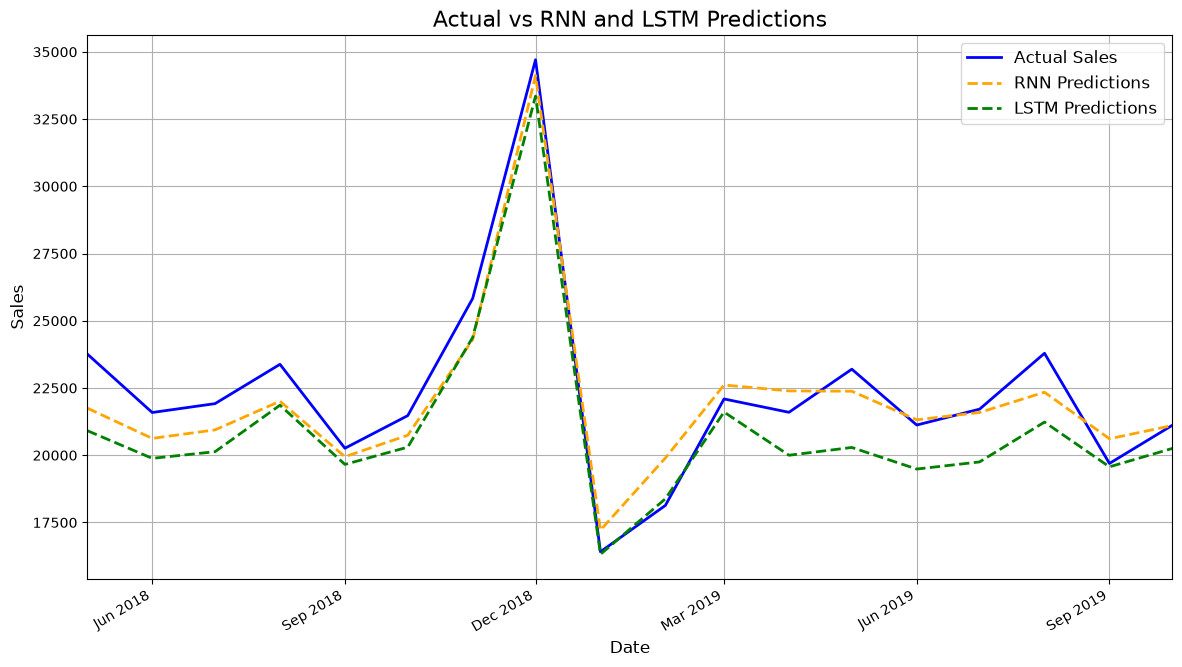

In [16]:
# Fungsi untuk plot prediksi RNN dan LSTM bersama data actual
def plot_predictions(test, sales_data, rnn_predictions, lstm_predictions):
    # Plot RNN and LSTM predictions along with actual sales
    plt.figure(figsize=(14, 8))
    plt.plot(test.index, test['Sales'], label='Actual Sales', color='blue', linewidth=2)
    plt.plot(test.index, test['RNN_Predictions'], label='RNN Predictions', color='orange', linestyle='--', linewidth=2)
    plt.plot(test.index, test['LSTM_Predictions'], label='LSTM Predictions', color='green', linestyle='--', linewidth=2)

    # Formatting the x-axis to show dates nicely
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    plt.gcf().autofmt_xdate()  # Rotate the x labels for better readability
    plt.title('Actual vs RNN and LSTM Predictions', fontsize=16)
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Sales', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.xlim([test.index[0], test.index[-1]])
    plt.show()

plot_predictions(test, sales_data, rnn_predictions, lstm_predictions)

#### Penjelasan :
##### Plot Perbandingan Prediksi RNN & LSTM vs Data Aktual
##### Pada sel kesebelas, program mendefinisikan serta memanggil fungsi visualisasi untuk membandingkan kurva penjualan aktual selama delapan belas bulan periode uji dengan garis putus-putus hasil prediksi jaringan berulang sederhana dan memori jangka panjang dalam satu grafik beresolusi tinggi. Sumbu mendatar diformat agar menampilkan singkatan bulan dan tahun dengan jarak tiga bulan serta dimiringkan supaya label tanggal terbaca rapi tanpa saling menumpuk. Keluaran grafik di layar memperlihatkan bahwa kedua model berhasil meniru irama naik-turun musiman penjualan asli termasuk lonjakan tajam bulan Desember tahun dua ribu delapan belas serta penurunan di awal tahun berikutnya.

In [17]:
# Membuat prediksi ke depan dengan model
def forecast_future(model, scaled_data, length, n_features, periods):
    forecast = []
    first_eval_batch = scaled_data[-length:]
    current_batch = first_eval_batch.reshape((1, length, n_features))

    for i in range(periods):
        current_pred = model.predict(current_batch)[0]
        forecast.append(current_pred)
        current_batch = np.append(current_batch[:, 1:, :], [[current_pred]], axis=1)

    return scaler.inverse_transform(forecast)

# Prediksi untuk 12 periode ke depan
forecast_rnn = forecast_future(model_rnn, scaled_train, length, n_features, periods=12)
forecast_lstm = forecast_future(model_lstm, scaled_train, length, n_features, periods=12)

# Membuat dataframe untuk forecast
forecast_index = pd.date_range(start='2019-11-01', periods=12, freq='MS')
forecast_rnn_data = pd.DataFrame(data=forecast_rnn, index=forecast_index, columns=['RNN_Forecast'])
forecast_lstm_data = pd.DataFrame(data=forecast_lstm, index=forecast_index, columns=['LSTM_Forecast'])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


#### Penjelasan :
##### Peramalan 12 Bulan ke Depan (Forecast Future)
##### Pada sel kedua belas, program membangun fungsi peramalan jangka panjang untuk memproyeksikan angka penjualan dua belas periode bulanan ke depan secara bergulir dimulai dari jendela dua belas bulan terakhir data latih lalu mengembalikan skalanya ke nilai penjualan sebenarnya. Hasil peramalan dari jaringan berulang sederhana maupun memori jangka panjang kemudian dipasangkan ke indeks tanggal awal bulan mulai bulan November tahun dua ribu sembilan belas hingga bulan Oktober tahun dua ribu dua puluh ke dalam dua tabel baru. Sel ini menyiapkan data proyeksi masa depan dari kedua model sehingga siap digabungkan dan digambar pada sel terakhir.

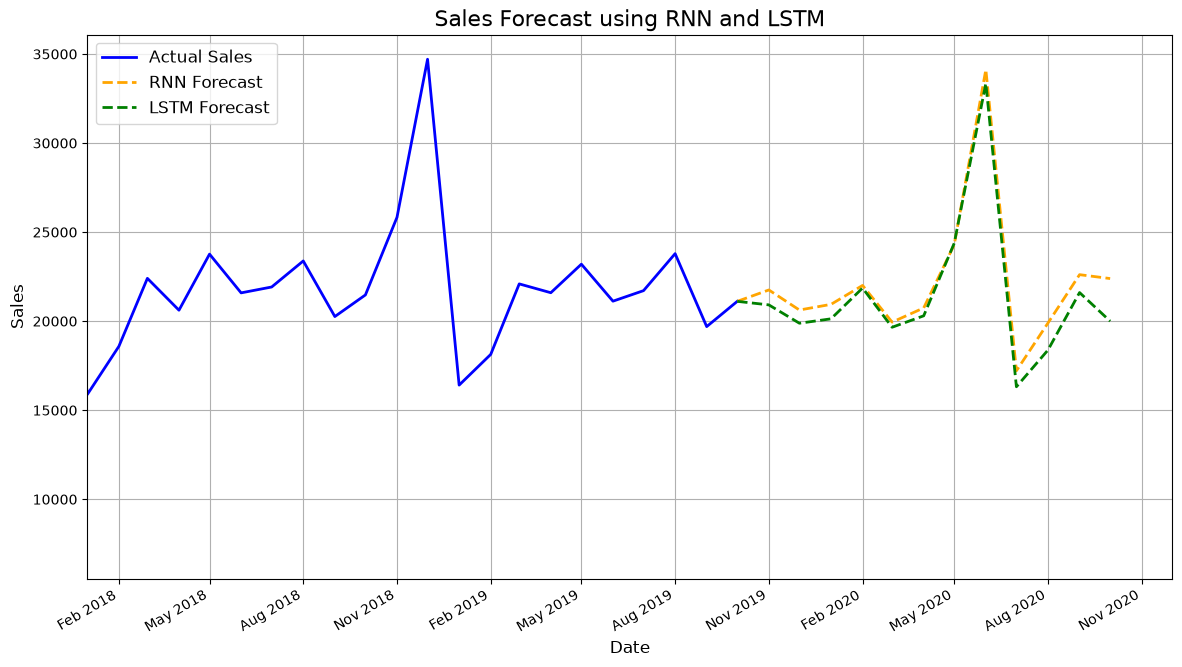

In [25]:
# Fungsi untuk plot forecast ke depan
def plot_forecast(sales_data, forecast_rnn_data, forecast_lstm_data):
    # Mendapatkan nilai dan index terakhir dari sales_data
    last_actual_value = sales_data['Sales'].iloc[-1]
    last_actual_date = sales_data.index[-1]

    # Menyusun prediksi agar dimulai tepat setelah data actual
    forecast_rnn_data.index = pd.date_range(start=last_actual_date + pd.DateOffset(months=1), periods=len(forecast_rnn_data), freq='MS')
    forecast_lstm_data.index = pd.date_range(start=last_actual_date + pd.DateOffset(months=1), periods=len(forecast_lstm_data), freq='MS')

    # Menambahkan nilai terakhir data actual sebagai titik awal prediksi
    forecast_rnn_data = pd.concat([pd.DataFrame({'RNN_Forecast': [last_actual_value]}, index=[last_actual_date]), forecast_rnn_data])
    forecast_lstm_data = pd.concat([pd.DataFrame({'LSTM_Forecast': [last_actual_value]}, index=[last_actual_date]), forecast_lstm_data])

    # Gabungkan data actual dan prediksi
    combined_rnn_data = pd.concat([sales_data, forecast_rnn_data], axis=0)
    combined_lstm_data = pd.concat([sales_data, forecast_lstm_data], axis=0)

    # Plot actual sales dan prediksi forecast
    plt.figure(figsize=(14, 8))

    # Plot actual sales
    plt.plot(sales_data.index, sales_data['Sales'], label='Actual Sales', color='blue', linewidth=2)

    # Plot RNN forecast
    plt.plot(forecast_rnn_data.index, forecast_rnn_data['RNN_Forecast'], label='RNN Forecast', color='orange', linestyle='--', linewidth=2)

    # Plot LSTM forecast
    plt.plot(forecast_lstm_data.index, forecast_lstm_data['LSTM_Forecast'], label='LSTM Forecast', color='green', linestyle='--', linewidth=2)

    # Set the limits for x-axis to control the date range
    plt.xlim(pd.to_datetime('2018-01-01'), pd.to_datetime('2020-12-01'))

    # Formatting the x-axis to show dates nicely
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))  # Show every 3 months
    plt.gcf().autofmt_xdate()

    plt.title('Sales Forecast using RNN and LSTM', fontsize=16)
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Sales', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()


# Contoh pemanggilan fungsi setelah model dijalankan
plot_forecast(sales_data, forecast_rnn_data, forecast_lstm_data)

#### Penjelasan :
##### Plot Gabungan Data Aktual dan Forecast 12 Bulan
##### Pada sel ketiga belas sekaligus sel penutup modul teori, program mendefinisikan dan menjalankan fungsi visualisasi akhir dengan terlebih dahulu menyisipkan nilai penjualan aktual terakhir beserta tanggalnya ke awal seri peramalan agar garis proyeksi jaringan berulang sederhana dan memori jangka panjang tersambung mulus tanpa celah terputus dengan kurva historis, lalu membatasi sumbu datar dari awal tahun dua ribu delapan belas sampai akhir tahun dua ribu dua puluh dengan pemformatan tanggal tiap tiga bulan. Keluaran grafik di layar memperlihatkan kesinambungan kurva historis biru dengan garis putus-putus proyeksi oranye dan hijau yang tetap menangkap pola puncak musiman penjualan di masa mendatang.